This document is focus on:

*   Model Deveopment




In [4]:
import pandas as pd

df = pd.read_csv("airbnb_toronto_listings_202607_summary.csv")
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,325432,"Great 'hood, no car needed, 3.5br",1664812.0,1.462564e+18,Mark,NaN,High Park North,43.66106,-79.45605,Entire home/apt,NaN,28,0,NaN,NaN,1.0,0,0,NaN
1,361557,Downtown/Stylish 2 Bdr. Apt /Garden +Parking,174063.0,1.462512e+18,Denis,NaN,South Parkdale,43.63557,-79.43999,Entire home/apt,NaN,750,65,2022-02-05,0.38,4.0,364,0,NaN
2,363057,Charming Century Cottage in Beaches,1816495.0,1.462521e+18,Katharine,NaN,The Beaches,43.67262,-79.30057,Entire home/apt,594.0,28,87,2024-08-25,0.79,1.0,78,0,STR-2203-GGLHHF
3,2042951,Victorian Home On Subway Faces Park,9880504.0,1.462826e+18,Rob,NaN,East End-Danforth,43.69080,-79.29496,Entire home/apt,NaN,180,0,NaN,NaN,2.0,89,0,NaN
4,3139898,Trendy 2 level apt with rooftop deck & free Wi-Fi,15943061.0,1.462974e+18,Carol,NaN,North Riverdale,43.66888,-79.35230,Entire home/apt,498.0,1,13,2026-06-14,0.09,1.0,306,5,STR-2602-HVLLBY


In [5]:
# remove columns which are not needed
df = df.drop(columns='neighbourhood_group')

In [7]:
# add license_numeric column: licensed = 1, not licensed = 0
# and drop the 'license' column
df['license_num'] = (df['license'].notna()).astype(int)
df[['license','license_num']]

df1 = df.loc[:, df.columns != 'license']
df1.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license_num
0,325432,"Great 'hood, no car needed, 3.5br",1664812.0,1.462564e+18,Mark,High Park North,43.66106,-79.45605,Entire home/apt,NaN,28,0,NaN,NaN,1.0,0,0,0
1,361557,Downtown/Stylish 2 Bdr. Apt /Garden +Parking,174063.0,1.462512e+18,Denis,South Parkdale,43.63557,-79.43999,Entire home/apt,NaN,750,65,2022-02-05,0.38,4.0,364,0,0
2,363057,Charming Century Cottage in Beaches,1816495.0,1.462521e+18,Katharine,The Beaches,43.67262,-79.30057,Entire home/apt,594.0,28,87,2024-08-25,0.79,1.0,78,0,1
3,2042951,Victorian Home On Subway Faces Park,9880504.0,1.462826e+18,Rob,East End-Danforth,43.69080,-79.29496,Entire home/apt,NaN,180,0,NaN,NaN,2.0,89,0,0
4,3139898,Trendy 2 level apt with rooftop deck & free Wi-Fi,15943061.0,1.462974e+18,Carol,North Riverdale,43.66888,-79.35230,Entire home/apt,498.0,1,13,2026-06-14,0.09,1.0,306,5,1


In [8]:
df1.duplicated(subset=['id']).sum()

np.int64(0)

In [9]:
cols_to_fill = ['reviews_per_month', 'calculated_host_listings_count']
df1[cols_to_fill] = df1[cols_to_fill].fillna(0)

df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22256 entries, 0 to 22255
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              22256 non-null  int64  
 1   name                            22256 non-null  object 
 2   host_id                         22212 non-null  float64
 3   host_profile_id                 22211 non-null  float64
 4   host_name                       22211 non-null  object 
 5   neighbourhood                   22256 non-null  object 
 6   latitude                        22256 non-null  float64
 7   longitude                       22256 non-null  float64
 8   room_type                       22256 non-null  object 
 9   price                           17592 non-null  float64
 10  minimum_nights                  22256 non-null  int64  
 11  number_of_reviews               22256 non-null  int64  
 12  last_review                     

/tmp/ipykernel_847/2156007569.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1[cols_to_fill] = df1[cols_to_fill].fillna(0)


In [32]:
# remove rows if don't have 'price'
df1.dropna(subset=['price'], inplace=True)
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17592 entries, 2 to 22255
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              17592 non-null  int64  
 1   name                            17592 non-null  object 
 2   host_id                         17557 non-null  float64
 3   host_profile_id                 17556 non-null  float64
 4   host_name                       17556 non-null  object 
 5   neighbourhood                   17592 non-null  object 
 6   latitude                        17592 non-null  float64
 7   longitude                       17592 non-null  float64
 8   room_type                       17592 non-null  object 
 9   price                           17592 non-null  float64
 10  minimum_nights                  17592 non-null  int64  
 11  number_of_reviews               17592 non-null  int64  
 12  last_review                     13943

/tmp/ipykernel_847/582295.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1.dropna(subset=['price'], inplace=True)


In [33]:
df1['price'].isnull().sum()

np.int64(0)

In [34]:
# start to seperate traning and testing dataset
# want to evaluate the relationship between 'price' and
# ['neighbourhood', 'room_type', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'license_num ']
X = df1[['neighbourhood', 'room_type', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'license_num']]
Y = df1['price']

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [102]:
from scipy import stats
# Group y_train by neighborhood categories
groups = [group.dropna() for _, group in y_train.groupby(X_train['neighbourhood'])]

# Run one-way ANOVA (F-statistic and p-value)
f_stat, p_val = stats.f_oneway(*groups)

print(f"F statistic: {f_stat:.4f}, p value: {p_val:.4e}")

F statistic: 6.8865, p value: 2.9787e-117


In [103]:
# Group y_train by room_type categories
groups = [group.dropna() for _, group in y_train.groupby(X_train['room_type'])]

# Run one-way ANOVA (F-statistic and p-value)
f_stat, p_val = stats.f_oneway(*groups)

print(f"F statistic: {f_stat:.4f}, p value: {p_val:.4e}")

F statistic: 377.1785, p value: 1.2126e-235


In [50]:
# convert categorial data to numeric for regression models
X_train['neighbourhood_mean'] = y_train.groupby(X_train['neighbourhood']).transform('mean')

# Extract the learned lookup table from train
lookup = y_train.groupby(X_train['neighbourhood']).mean()
global_mean = y_train.mean()

X_test['neighbourhood_mean'] = X_test['neighbourhood'].map(lookup).fillna(global_mean)

In [52]:
X_train['room_type_mean'] = y_train.groupby(X_train['room_type']).transform('mean')

# Extract the learned lookup table from train
lookup = y_train.groupby(X_train['room_type']).mean()

X_test['room_type_mean'] = X_test['room_type'].map(lookup).fillna(global_mean)

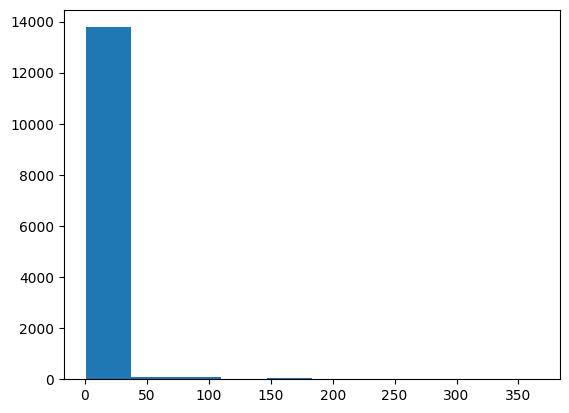

In [105]:
# evaluate skewness
plt.hist(X_train['minimum_nights'])
plt.show()

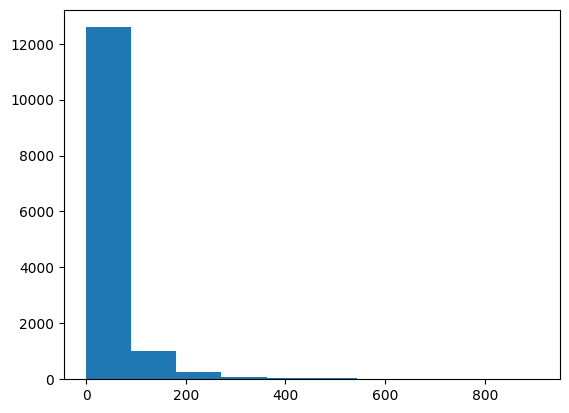

In [106]:
plt.hist(X_train['number_of_reviews'])
plt.show()

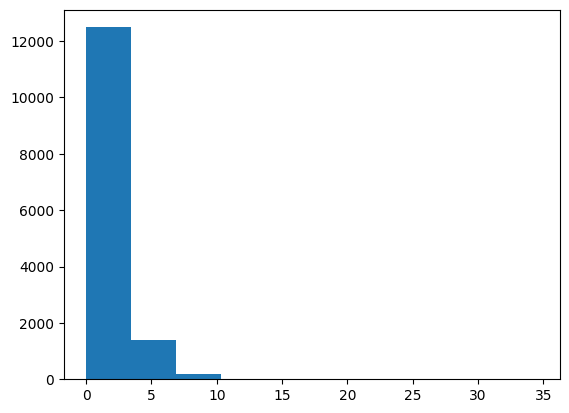

In [107]:
plt.hist(X_train['reviews_per_month'])
plt.show()

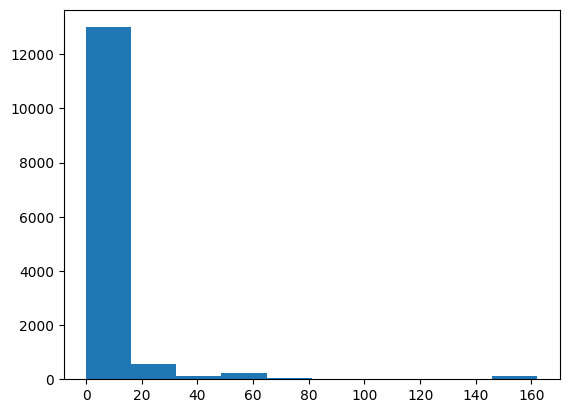

In [108]:
plt.hist(X_train['calculated_host_listings_count'])
plt.show()

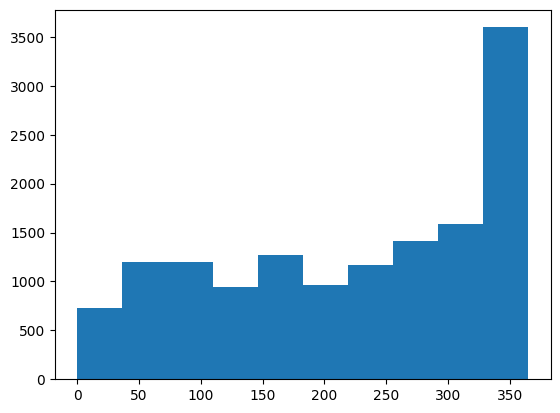

In [109]:
plt.hist(X_train['availability_365'])
plt.show()

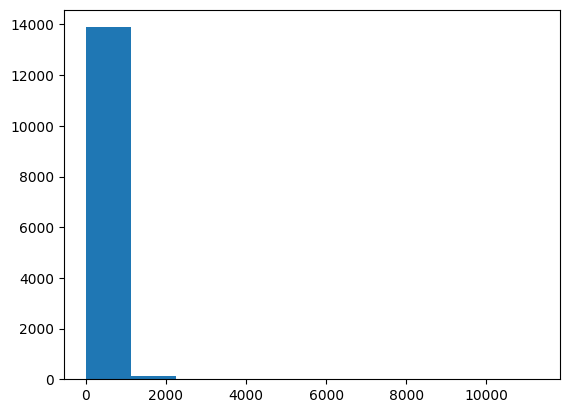

In [111]:
plt.hist(y_train)
plt.show()

In [112]:
# transform value using log
import numpy as np

cols_to_log = ['minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
# generates new columns: minimum_nights_log, etc.
for col in cols_to_log:
    X_train[f"{col}_log"] = np.log1p(X_train[col])
    X_test[f"{col}_log"] = np.log1p(X_test[col])

X_train.head()

,neighbourhood,room_type,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,license_num,neighbourhood_mean,room_type_mean,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log,availability_365_log
16517,Waterfront Communities-The Island,Private room,28,0,0.00,5.0,344,0,369.287323,120.833001,3.367296,0.000000,0.000000,1.791759,5.843544
2874,Lawrence Park South,Entire home/apt,30,77,0.77,43.0,240,0,519.372549,327.520640,3.433987,4.356709,0.570980,3.784190,5.484797
15738,Church-Yonge Corridor,Entire home/apt,1,8,1.21,1.0,334,1,329.607219,327.520640,0.693147,2.197225,0.792993,0.693147,5.814131
7877,Roncesvalles,Private room,28,22,0.48,1.0,179,1,243.408000,120.833001,3.367296,3.135494,0.392042,0.693147,5.192957
11230,Roncesvalles,Entire home/apt,28,9,0.34,3.0,133,0,243.408000,327.520640,3.367296,2.302585,0.292670,1.386294,4.897840


In [116]:
# log for price
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

In [75]:
# train for linear regression
from sklearn.linear_model import LinearRegression

lm = LinearRegression()

In [118]:
X1 = X_train[['neighbourhood_mean', 'room_type_mean', 'minimum_nights_log', 'number_of_reviews_log', 'reviews_per_month_log', 'calculated_host_listings_count_log', 'availability_365_log']]
lm.fit(X1,y_train_log)


LinearRegression()

In [119]:
# predict
X2 = X_test[['neighbourhood_mean', 'room_type_mean', 'minimum_nights_log', 'number_of_reviews_log', 'reviews_per_month_log', 'calculated_host_listings_count_log', 'availability_365_log']]
Y1_hat = lm.predict(X2)
Y1_train_hat = lm.predict(X1)

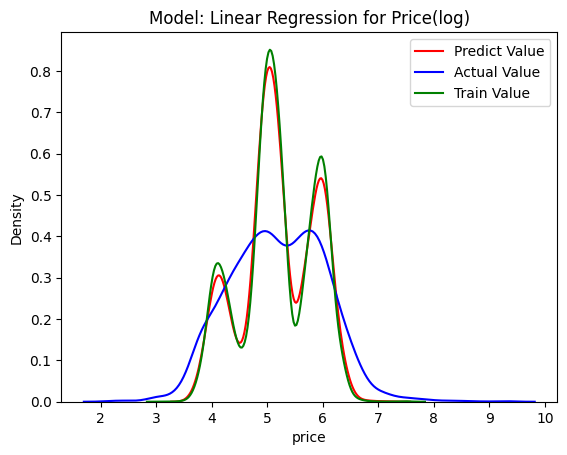

In [120]:
# draw a distribution plot
import seaborn as sns
import matplotlib.pyplot as plt

sns.kdeplot(Y1_hat, color='red')
sns.kdeplot(y_test_log, color='blue')
sns.kdeplot(Y1_train_hat, color='green')

plt.title("Model: Linear Regression for Price(log)")
plt.legend(labels=['Predict Value', 'Actual Value', 'Train Value'])
plt.show()

In [122]:
# train for Multi-variate Polynomial Regression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures

Input3=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(degree=3, include_bias=False)), ('model',LinearRegression())]

pipe3=Pipeline(Input3)

pipe3.fit(X1,y_train_log)
y_pipe3 = pipe3.predict(X2)
y_pipe3_train = pipe3.predict(X1)


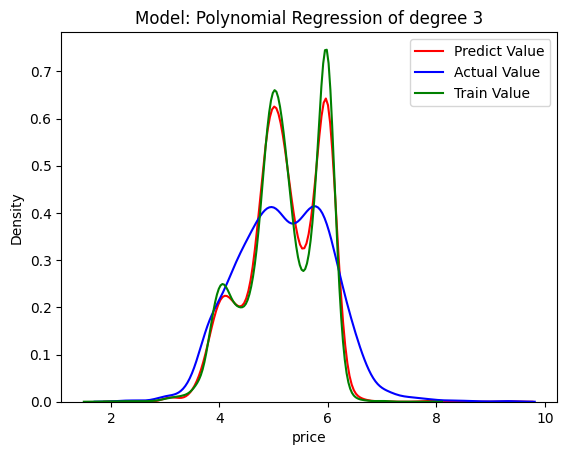

In [125]:
sns.kdeplot(y_pipe3, color='red')
sns.kdeplot(y_test_log, color='blue')
sns.kdeplot(y_pipe3_train, color='green')

plt.title("Model: Polynomial Regression of degree 3")
plt.legend(labels=['Predict Value', 'Actual Value', 'Train Value'])
plt.show()

In [124]:
Input5=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(degree=5, include_bias=False)), ('model',LinearRegression())]

pipe5=Pipeline(Input5)

pipe5.fit(X1,y_train)
y_pipe5 = pipe5.predict(X2)
y_pipe5_train = pipe5.predict(X1)

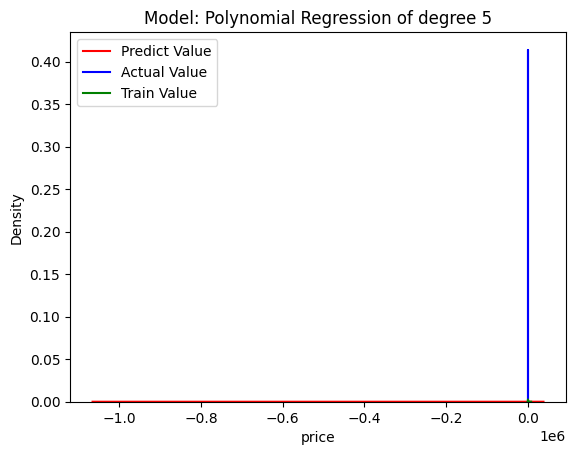

In [127]:
sns.kdeplot(y_pipe5, color='red')
sns.kdeplot(y_test_log, color='blue')
sns.kdeplot(y_pipe5_train, color='green')

plt.title("Model: Polynomial Regression of degree 5")
plt.legend(labels=['Predict Value', 'Actual Value', 'Train Value'])
plt.show()

In [131]:
Input4=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(degree=4, include_bias=False)), ('model',LinearRegression())]

pipe4=Pipeline(Input4)

pipe4.fit(X1,y_train_log)
y_pipe4 = pipe4.predict(X2)
y_pipe4_train = pipe4.predict(X1)

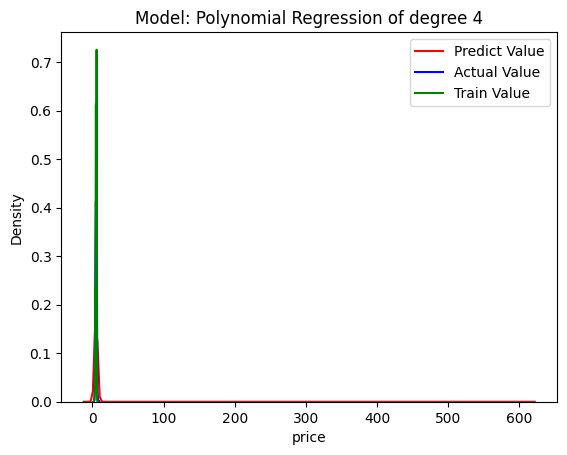

In [132]:
sns.kdeplot(y_pipe4, color='red')
sns.kdeplot(y_test_log, color='blue')
sns.kdeplot(y_pipe4_train, color='green')

plt.title("Model: Polynomial Regression of degree 4")
plt.legend(labels=['Predict Value', 'Actual Value', 'Train Value'])
plt.show()

In [139]:
# calculate MSE
# inverted back the log of price
from sklearn.metrics import mean_squared_error

mse_lr = mean_squared_error(y_test_log, Y1_hat)
mse_p3 = mean_squared_error(y_test_log, y_pipe3)
mse_p4 = mean_squared_error(y_test_log, y_pipe4)
mse_p5 = mean_squared_error(y_test_log, y_pipe5)

print(f"mean-squared error for linear regression is: {mse_lr}")
print(f"mean-squared error for polynomial regression degree 3 is: {mse_p3}")
print(f"mean-squared error for polynomial regression degree 4 is: {mse_p4}")
print(f"mean-squared error for polynomial regression degree 5 is: {mse_p5}")

mean-squared error for linear regression is: 0.3051300206157465
mean-squared error for polynomial regression degree 3 is: 0.268912400858138
mean-squared error for polynomial regression degree 4 is: 105.60201845014095
mean-squared error for polynomial regression degree 5 is: 321027797.23061985


In [134]:
# calcaulate r^2 value for linear regression
r2_lr_train = lm.score(X1, y_train_log)
r2_lr_test = lm.score(X2, y_test_log)
print(f"r^2 value for train: {r2_lr_train}")
print(f"r^2 value for test: {r2_lr_test}")

r^2 value for train: 0.5962758479381554
r^2 value for test: 0.5799623070833564


In [135]:
# calcaulate r^2 value for polynomial regression
from sklearn.metrics import r2_score

r2_pr_3_train = pipe3.score(X1, y_train_log)
r2_pr_3_test = pipe3.score(X2, y_test_log)

r2_pr_4_train = pipe4.score(X1, y_train_log)
r2_pr_4_test = pipe4.score(X2, y_test_log)

r2_pr_5_train = pipe5.score(X1, y_train_log)
r2_pr_5_test = pipe5.score(X2, y_test_log)

print("degree of 3 ------")
print(f"r^2 value for train: {r2_pr_3_train}")
print(f"r^2 value for test: {r2_pr_3_test}")

print("degree of 4 ------")
print(f"r^2 value for train: {r2_pr_4_train}")
print(f"r^2 value for test: {r2_pr_4_test}")

print("degree of 5 ------")
print(f"r^2 value for train: {r2_pr_5_train}")
print(f"r^2 value for test: {r2_pr_5_test}")

degree of 3 ------
r^2 value for train: 0.6516636319464844
r^2 value for test: 0.6298189728261079
degree of 4 ------
r^2 value for train: 0.6650490964684546
r^2 value for test: -144.37025267991265
degree of 5 ------
r^2 value for train: -139064.77591218235
r^2 value for test: -441922347.508185
